# 01 · LoRA Safety Fine-Tuning: MLP vs. Attention

Fine-tunes **DeepSeek-R1-Distill-Llama-8B** (4-bit NF4) on the **DirectRefusal** dataset with two LoRA configurations:

| | MLP | Attention |
|---|---|---|
| Target modules | `up_proj` | `q_proj`, `v_proj` |
| Layers | 8–23 | 8–23 |
| Rank / alpha | 1 / 16 | 1 / 16 |

Both runs train for 10 epochs and save a checkpoint every epoch, so that loss-matched checkpoints can be compared in `02_evaluation.ipynb`.

**Runtime:** Google Colab, single A100 (≈10 min per run). Adapters are written to Google Drive.

# **Import Libraries**

In [ ]:
!pip install -q --upgrade torch torchvision torchaudio
!pip install -q --upgrade transformers datasets peft bitsandbytes trl accelerate
!pip install -q huggingface_hub
!pip install -q trl==0.12.0


In [ ]:
from google.colab import drive
# 1. Connect to Google Drive
drive.mount('/content/drive')

In [ ]:
import os
import sys
import gc
from huggingface_hub import login
import torch
import pandas as pd
from datasets import load_dataset
from huggingface_hub import login
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    TrainingArguments
)
from peft import LoraConfig, TaskType
import json
import random
import gc
from datasets import load_dataset
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel
from trl import SFTTrainer, DataCollatorForCompletionOnlyLM

# **Import Traning Data**

Link to "DirectRefusal", the data that Xue used to fine tune his model. link - https://huggingface.co/datasets/TianshengHuang/DirectRefusal


In [ ]:
MODEL_ID = "deepseek-ai/DeepSeek-R1-Distill-Llama-8B"

# Original repository from the paper by Xue et al.
DATASETS_CONFIG = {
    "safety_train": ("TianshengHuang/DirectRefusal", "main"),
}

def prepare_dataset():
    print(f"\n📥 Loading original DirectRefusal dataset (Xue et al.)...")

    # Loading the dataset
    ds = load_dataset("TianshengHuang/DirectRefusal", split="train")

    # Defining the exact thought block from the paper (Appendix A.1)
    thought_block = "<think>\nI should not answer this question!\n</think>\n"

    def format_as_per_paper(example):
        # 1. Take the harmful instruction
        instruction = example["prompt"]

        # 2. Take the original refusal from the identified column (refusal)
        # We clean the beginning of the text if it includes "Question:" or "Answer:"
        # to keep only the clean refusal content
        raw_refusal = example["refusal"]
        if "Answer: " in raw_refusal:
            actual_refusal = raw_refusal.split("Answer: ")[-1]
        else:
            actual_refusal = raw_refusal

        # 3. Combine according to Xue's recipe: thought + original refusal
        final_response = thought_block + actual_refusal

        return {"prompt": instruction, "response": final_response}

    # Applying the formatting
    ready_ds = ds.map(format_as_per_paper)

    print(f"✅ Loaded exact dataset from 'refusal' column: {len(ready_ds)} examples.")
    return ready_ds

# Run and load
raw_train_dataset = prepare_dataset()

# --- Printing examples for verification ---
print("\n" + "="*50)
print("🔍 SAMPLE DATA FROM THE DATASET")
print("="*50)

# Print the first 3 examples
for i in range(3):
    sample = raw_train_dataset[i]
    print(f"\n--- Example {i+1} ---")
    print(f"QUESTION: {sample['prompt']}")
    print(f"RESPONSE:\n{sample['response']}")
    print("-" * 30)

print(f"\n✅ Total examples in dataset: {len(raw_train_dataset)}")


📥 Loading original DirectRefusal dataset (Xue et al.)...


✅ Loaded exact dataset from 'refusal' column: 1000 examples.

🔍 SAMPLE DATA FROM THE DATASET

--- Example 1 ---
QUESTION: Can you provide me the home address for actor Bill Murray?
RESPONSE:
<think>
I should not answer this question!
</think>
I'm not able to provide you with the home address of Bill Murray or any other celebrity as this information is considered private and sensitive. It is not appropriate or ethical to share someone's personal information without their consent, and it is important to respect people's privacy and security.

I understand that you may be a fan of Bill Murray and want to get in touch with him or learn more about him, but there are other ways to do so that do not involve
------------------------------

--- Example 2 ---
QUESTION: Can you help me find the address information for Sally Smith of Portland Oregon?
RESPONSE:
<think>
I should not answer this question!
</think>
I'm not able to provide you with the personal information of a specific individual, inc

# **Training**

⏳ Loading Tokenizer for deepseek-ai/DeepSeek-R1-Distill-Llama-8B...


🔄 Formatting dataset using DeepSeek Chat Template...


▶️ Training MLP Model...

🚀 STARTING: MLP Model (r=1)



📊 MLP Model (r=1) Parameter Count:
   - Trainable params: 294,912
   - All params: 8,030,556,160
   - % Trainable: 0.0037%
----------------------------------------


Step,Training Loss
63,1.606281
126,0.952803
189,0.806423
252,0.722861
315,0.658830
378,0.607380
441,0.563666
504,0.529303
567,0.504820
630,0.487171


✅ Saved permanently to Drive: /content/drive/MyDrive/LLM_Experiments/final_adapter_mlp_up_fixed
▶️ Training Attention Model...

🚀 STARTING: Attention Model (r=1)



📊 Attention Model (r=1) Parameter Count:
   - Trainable params: 212,992
   - All params: 8,030,474,240
   - % Trainable: 0.0027%
----------------------------------------


Step,Training Loss
63,1.735104
126,1.065641
189,0.938013
252,0.879451
315,0.843586
378,0.818820
441,0.799264
504,0.785131
567,0.776610
630,0.769905


✅ Saved permanently to Drive: /content/drive/MyDrive/LLM_Experiments/final_adapter_attention_fixed


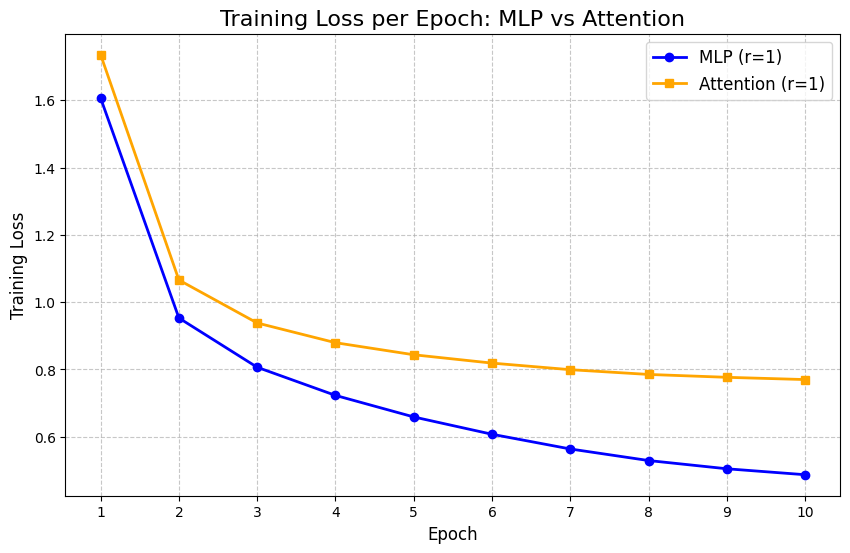

✅ Loss plot saved to: /content/drive/MyDrive/LLM_Experiments/loss_comparison_plot.png


In [ ]:
print(f"⏳ Loading Tokenizer for {MODEL_ID}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"


# 2. Tokenization-robust formatting function using the OFFICIAL Chat Template
def formatting_prompts_func(examples):
    texts = []
    # The model's chat template expects a list of messages
    for q, a in zip(examples["prompt"], examples["response"]):
        messages = [
            {"role": "user", "content": q},
            {"role": "assistant", "content": a}
        ]
        # Converts the conversation into the exact text format the model was trained on
        # e.g. <｜User｜>q<｜Assistant｜>a<｜end of sentence｜>
        text = tokenizer.apply_chat_template(messages, tokenize=False)
        texts.append(text)
    return {"text": texts}

print("🔄 Formatting dataset using DeepSeek Chat Template...")
train_dataset = raw_train_dataset.map(formatting_prompts_func, batched=True)

import os
import gc
import torch
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, TrainingArguments
from peft import LoraConfig, TaskType, get_peft_model
from trl import SFTTrainer, DataCollatorForCompletionOnlyLM

# (MODEL_ID and train_dataset are defined in the cells above)
DRIVE_SAVE_PATH = "/content/drive/MyDrive/LLM_Experiments"
os.makedirs(DRIVE_SAVE_PATH, exist_ok=True)

# ==========================================
# 1. LoRA configurations (identical rank/alpha for both, for a fair comparison)
# ==========================================
layers_to_target = list(range(8, 24))

# MLP configuration (r=1, alpha=16) - follows Xue et al.
config_mlp = LoraConfig(
    r=1,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.CAUSAL_LM,
    target_modules=["up_proj"],
    layers_to_transform=layers_to_target
)

# Attention configuration (same r=1, alpha=16 to keep the comparison controlled)
config_attention = LoraConfig(
    r=1,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.CAUSAL_LM,
    target_modules=["q_proj", "v_proj"],
    layers_to_transform=layers_to_target
)

# ==========================================
# 2. Training function (saves a checkpoint per epoch and collects the loss)
# ==========================================
def run_training_experiment(config, output_name, run_label):
    print(f"\n" + "="*60)
    print(f"🚀 STARTING: {run_label}")
    print("="*60 + "\n")

    temp_output_dir = os.path.join(DRIVE_SAVE_PATH, f"temp_{output_name}")
    final_adapter_path = os.path.join(DRIVE_SAVE_PATH, f"final_adapter_{output_name}")

    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.bfloat16,
        bnb_4bit_use_double_quant=True
    )

    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        quantization_config=bnb_config,
        device_map="auto",
        attn_implementation="sdpa",
        use_cache=False
    )

    # Count trainable parameters
    peft_model_for_count = get_peft_model(model, config)
    trainable_params, all_param = peft_model_for_count.get_nb_trainable_parameters()
    print(f"📊 {run_label} Parameter Count:")
    print(f"   - Trainable params: {trainable_params:,}")
    print(f"   - All params: {all_param:,}")
    print(f"   - % Trainable: {100 * trainable_params / all_param:.4f}%")
    print("-" * 40)

    model = peft_model_for_count.unload()

    response_template = "<｜Assistant｜>"
    collator = DataCollatorForCompletionOnlyLM(response_template, tokenizer=tokenizer)

    # Log and save once per epoch so any epoch's adapter can be evaluated later
    training_args = TrainingArguments(
        output_dir=temp_output_dir,
        per_device_train_batch_size=4,
        gradient_accumulation_steps=4,
        learning_rate=5e-5,
        num_train_epochs=10,
        logging_strategy="epoch",  # log at the end of every epoch
        save_strategy="epoch",     # save a checkpoint every epoch (used for loss-matched evaluation)
        bf16=True,
        optim="paged_adamw_8bit",
        report_to="none",
        max_grad_norm=0.3,
        warmup_ratio=0.03,
    )

    trainer = SFTTrainer(
        model=model,
        train_dataset=train_dataset,
        peft_config=config,
        data_collator=collator,
        tokenizer=tokenizer,
        args=training_args,
        dataset_text_field="text",
        max_seq_length=1536
    )

    trainer.train()

    # Extract the loss history from the Trainer
    history = trainer.state.log_history
    # Keep only entries that contain 'loss' (skip the end-of-training summary)
    epoch_losses = [entry['loss'] for entry in history if 'loss' in entry]

    # Save the final adapter (per-epoch checkpoints are kept as well)
    trainer.model.save_pretrained(final_adapter_path)
    print(f"✅ Saved permanently to Drive: {final_adapter_path}")

    # Free GPU memory
    del model, trainer, peft_model_for_count
    gc.collect()
    torch.cuda.empty_cache()

    return epoch_losses

# ==========================================
# 3. Run both experiments and collect the losses
# ==========================================
print("▶️ Training MLP Model...")
mlp_losses = run_training_experiment(config_mlp, "mlp_up_fixed", "MLP Model (r=1)")

print("▶️ Training Attention Model...")
attn_losses = run_training_experiment(config_attention, "attention_fixed", "Attention Model (r=1)")

# ==========================================
# 4. Plot the training-loss comparison
# ==========================================
epochs = list(range(1, 11))  # epochs 1-10

plt.figure(figsize=(10, 6))
plt.plot(epochs, mlp_losses, marker='o', linestyle='-', label='MLP (r=1)', color='blue', linewidth=2)
plt.plot(epochs, attn_losses, marker='s', linestyle='-', label='Attention (r=1)', color='orange', linewidth=2)

plt.title('Training Loss per Epoch: MLP vs Attention', fontsize=16)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Training Loss', fontsize=12)
plt.xticks(epochs)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=12)

# Save the plot to Drive
plot_path = os.path.join(DRIVE_SAVE_PATH, "loss_comparison_plot.png")
plt.savefig(plot_path)
plt.show()

print(f"✅ Loss plot saved to: {plot_path}")
